# Housing Momentum Forecaster: every graph, with its code

This notebook draws every chart in the project from the results the pipeline saves to GitHub each month, so the numbers always match the [live dashboard](https://housing-momentum-forecaster.streamlit.app/) and the report.

**Run it:** Runtime → Run all (about 2 minutes, mostly the logistic regression in section 3). Nothing needs to be installed and no keys are needed.

| Section | Graphs |
| --- | --- |
| 1. Does the score work? | model comparison, accuracy by market period, score bands, 2022 case study, latest ranking |
| 2. Which web data helps? | signal tests, what predicts, search vs. no search, search lead time, news test, search by region |
| 3. Model evaluation with logistic regression | accuracy table, ROC curves, confusion matrices |
| 4. Dashboard views | market map, one metro's score history |

Code and data: [github.com/michaelnun/housingmomentumforecaster](https://github.com/michaelnun/housingmomentumforecaster)

## 0. Setup
Downloads the project from GitHub (code, data and saved results) and sets a common chart style.

In [1]:
import os, sys, subprocess, json, warnings
warnings.filterwarnings("ignore")
REPO = "https://github.com/michaelnun/housingmomentumforecaster"
if not os.path.exists("housingmomentumforecaster"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO], check=True)
os.chdir("housingmomentumforecaster")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

R = "results/"
GREEN, RED, INK, MUTED, GRID, GREY, BLUE = "#2F6B45", "#B5533C", "#1E2421", "#5E6863", "#E6E9E7", "#B8BFBB", "#2a78d6"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "figure.dpi": 110})
track = json.load(open(R + "track_record.json"))
print("Scores as of", track.get("as_of"), "| metros:", track.get("metros"), "| months tested:", track.get("months_tested"))

Scores as of Sep 2026 | metros: 45 | months tested: 74


## 1. Does the score work?
Every forecast was made month by month from May 2020, using only data available at the time (walk-forward testing). "Trend continues" assumes each metro's last 3 months repeat; it is the bar to beat.

### 1a. Model comparison
Ranking accuracy = rank correlation between forecast and actual growth vs. the typical metro, averaged over months. Top-5 hit rate = share of the 5 top-ranked metros that ended up in the actual top 5.

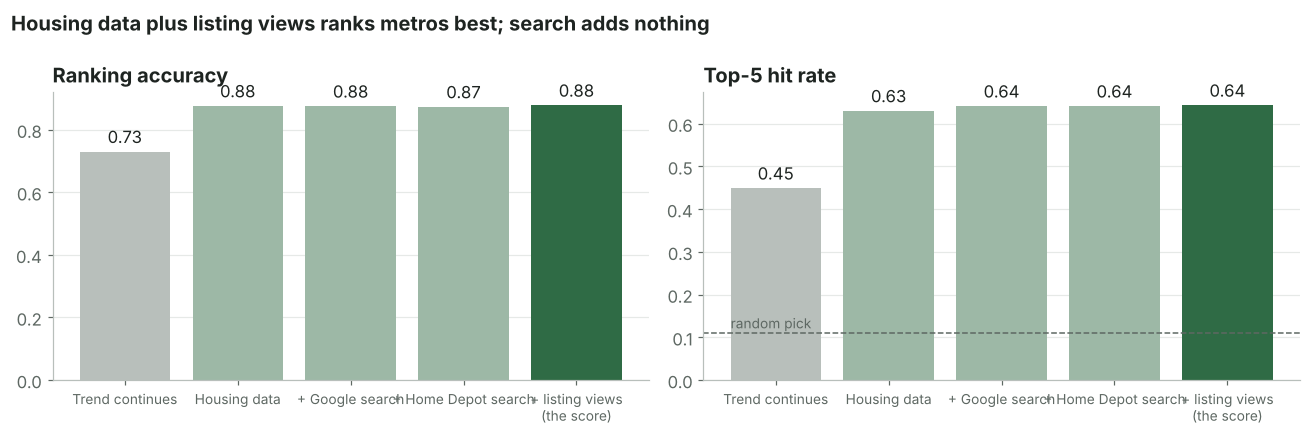

In [2]:
card = pd.read_csv(R + "scorecard.csv", index_col=0)
names = {"Naive": "Trend continues", "A": "Housing data", "B": "+ Google search",
         "C": "+ Home Depot search", "P": "+ listing views\n(the score)"}
card = card.loc[[m for m in names if m in card.index]]
colors = [GREY if m == "Naive" else (GREEN if m == "P" else "#9DB8A6") for m in card.index]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ["rank_corr", "top5_hit_rate"], ["Ranking accuracy", "Top-5 hit rate"]):
    bars = ax.bar([names[m] for m in card.index], card[metric], color=colors)
    ax.bar_label(bars, fmt="%.2f", padding=3, color=INK)
    ax.set_title(title, loc="left", fontweight="bold", color=INK)
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
axes[1].axhline(5 / track["metros"], ls="--", color=MUTED, lw=1)
axes[1].text(-0.4, 5 / track["metros"] + 0.01, "random pick", fontsize=9, color=MUTED)
fig.suptitle("Housing data plus listing views ranks metros best; search adds nothing",
             x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); plt.show()

### 1b. Ranking accuracy by market period

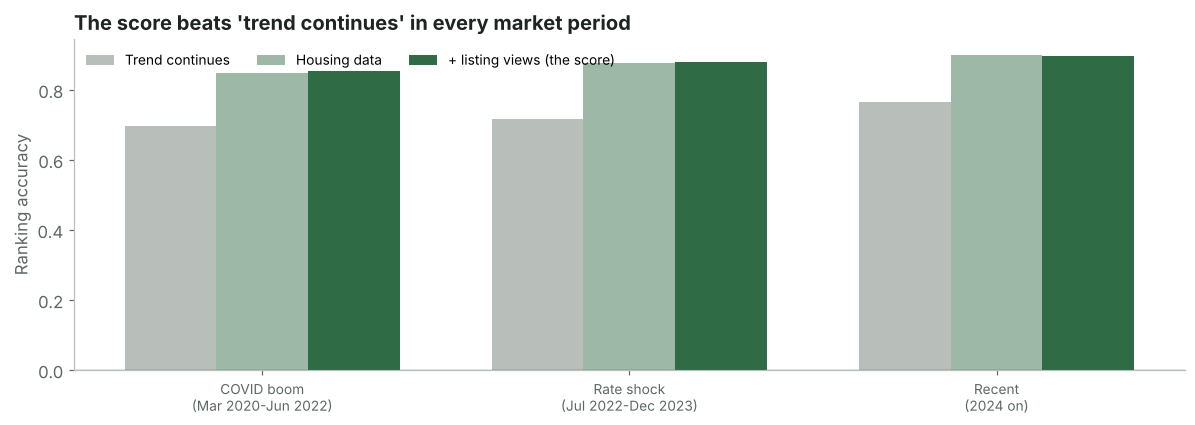

In [3]:
per = pd.read_csv(R + "scorecard_by_period.csv")
models = [m for m in ["Naive", "A", "P"] if m in per["model"].unique()]
pers = list(dict.fromkeys(per["period"]))
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.25
for i, m in enumerate(models):
    v = [per[(per.period == p) & (per.model == m)]["rank_corr"].mean() for p in pers]
    ax.bar(np.arange(len(pers)) + (i - 1) * w, v, w, label=names[m].replace("\n", " "),
           color=[GREY, "#9DB8A6", GREEN][i])
ax.set_xticks(np.arange(len(pers)), [p.replace(" (", "\n(") for p in pers], fontsize=9)
ax.axhline(0, color=INK, lw=0.8)
ax.set_title("The score beats 'trend continues' in every market period", loc="left", fontweight="bold", color=INK)
ax.set_ylabel("Ranking accuracy")
ax.legend(frameon=False, fontsize=9, ncol=3)
fig.tight_layout(); plt.show()

### 1c. Higher score, better next 3 months
Average growth over the next 3 months vs. the typical metro, by score band.

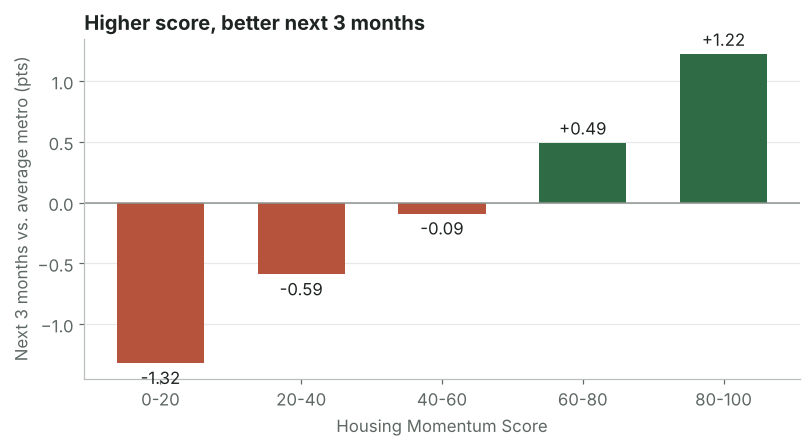

In [4]:
bands = pd.read_csv(R + "score_bands.csv")
vals = bands["avg_next_3m_vs_avg_pct"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(bands["band"], vals, color=[RED if v < 0 else GREEN for v in vals], width=0.62)
ax.bar_label(bars, labels=[f"{v:+.2f}" for v in vals], padding=3, color=INK)
ax.axhline(0, color="#8C958F", lw=1)
ax.set_xlabel("Housing Momentum Score"); ax.set_ylabel("Next 3 months vs. average metro (pts)")
ax.set_title("Higher score, better next 3 months", loc="left", fontweight="bold", color=INK)
ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

### 1d. Case study: the 2022 rate shock
The score fell as Sun Belt prices peaked, and rose before Chicago and Boston started beating the average.

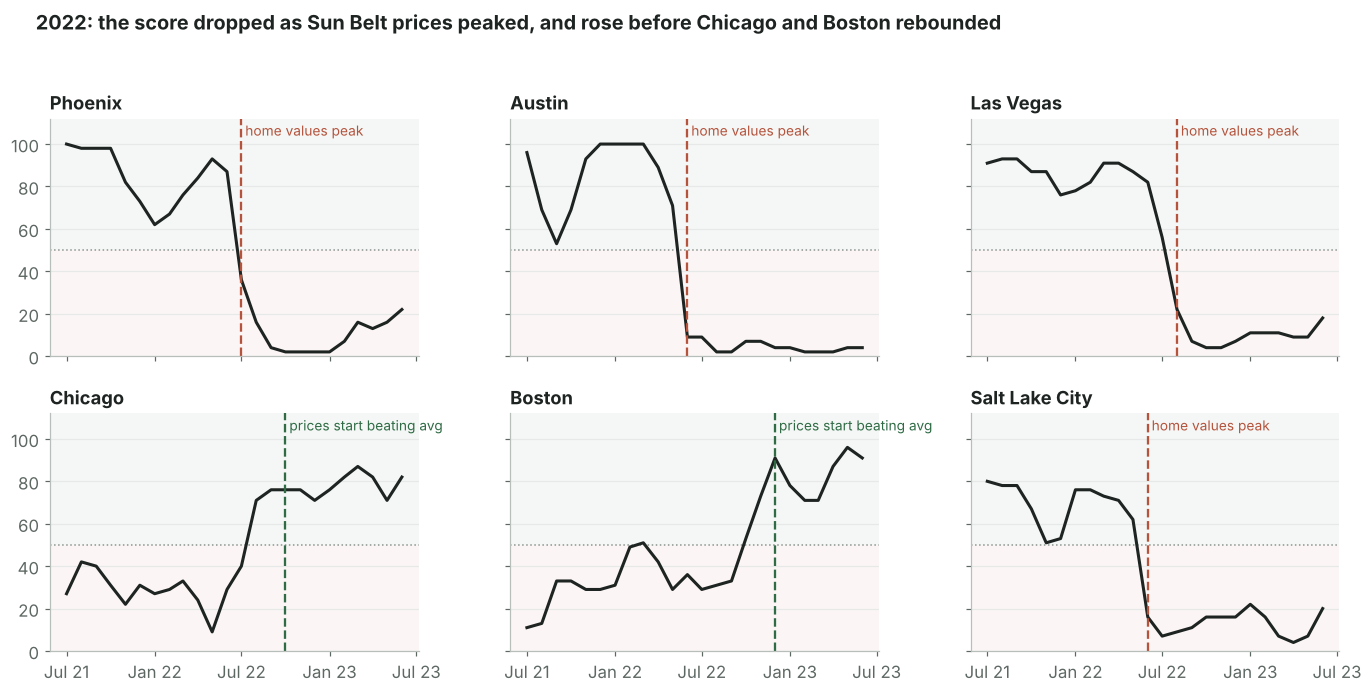

In [5]:
cs = pd.read_csv(R + "case_study_2022.csv", parse_dates=["date"])
L = pd.read_csv(R + "turning_points.csv", parse_dates=["date"])
CASE_DOWN, CASE_UP = ["Phoenix", "Austin", "Las Vegas", "Salt Lake City"], ["Chicago", "Boston"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True, sharey=True)
for ax, metro in zip(axes.flat, CASE_DOWN[:3] + CASE_UP + CASE_DOWN[3:]):
    d = cs[cs.metro == metro].set_index("date").reindex(pd.date_range("2021-07-01", "2023-06-01", freq="MS"))
    ax.axhspan(50, 112, color=GREEN, alpha=0.05, lw=0); ax.axhspan(0, 50, color=RED, alpha=0.05, lw=0)
    ax.axhline(50, color="#8C958F", lw=1, ls=":")
    ax.plot(d.index, d["score"], color=INK, lw=2)
    if metro in CASE_UP:
        flip = L[(L.metro == metro) & (L.direction == "up") & (L.date >= "2022-06-01") & (L.date <= "2023-03-01")]
        mark, label, col = (flip["date"].iloc[0] if len(flip) else None), " prices start beating avg", GREEN
    else:
        mark, label, col = d["zhvi"].idxmax(), " home values peak", RED
    if mark is not None:
        ax.axvline(mark, color=col, lw=1.5, ls="--"); ax.text(mark, 104, label, color=col, fontsize=9)
    ax.set_title(metro, loc="left", fontsize=12, fontweight="bold", color=INK)
    ax.set_ylim(0, 112); ax.grid(axis="y", color=GRID)
    ax.xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %y"))
fig.suptitle("2022: the score dropped as Sun Belt prices peaked, and rose before Chicago and Boston rebounded",
             x=0.06, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout(rect=(0.03, 0, 1, 0.95)); plt.show()

### 1e. The latest ranking
Predicted growth over the next 3 months vs. the typical metro.

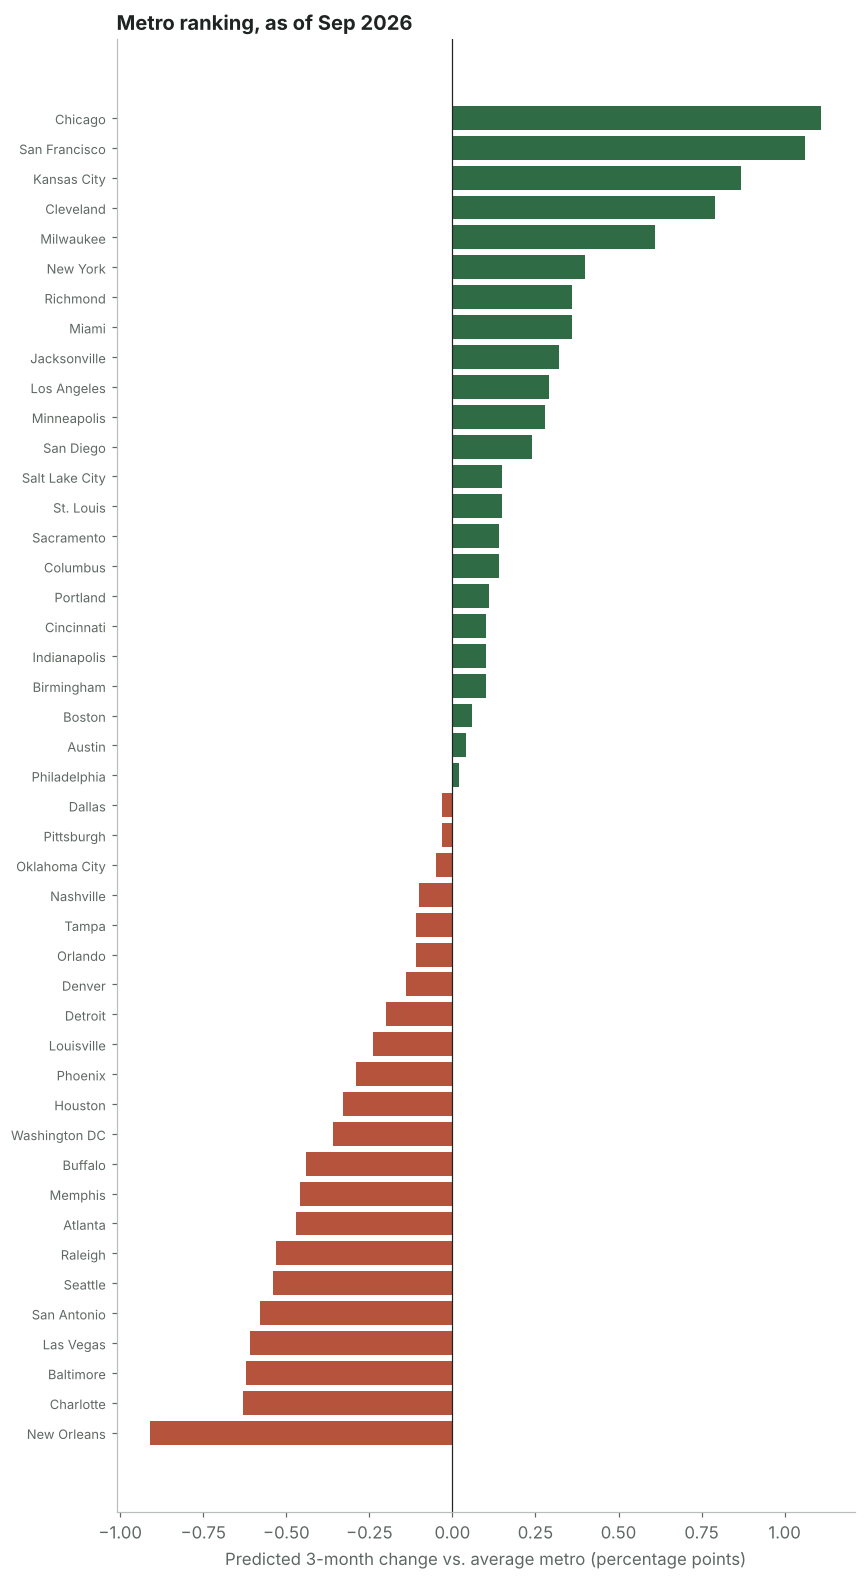

In [6]:
r = pd.read_csv(R + "ranked_list_latest.csv").sort_values("predicted_vs_avg_pct")
fig, ax = plt.subplots(figsize=(8, 0.3 * len(r) + 1))
ax.barh(r["metro"], r["predicted_vs_avg_pct"], color=np.where(r["predicted_vs_avg_pct"] >= 0, GREEN, RED))
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Predicted 3-month change vs. average metro (percentage points)")
ax.set_title(f"Metro ranking, as of {r['as_of'].iloc[0]}", loc="left", fontweight="bold", color=INK)
ax.tick_params(axis="y", labelsize=8.5)
fig.tight_layout(); plt.show()

## 2. Which web data helps?
Each web signal was added to the housing-data model and tested the same walk-forward way. The rule for passing was written down before the data was downloaded (`docs/` in the repository).

### 2a. Signal tests: does adding the signal improve the forecast?
Filled dot = statistically significant improvement (p < 0.05).

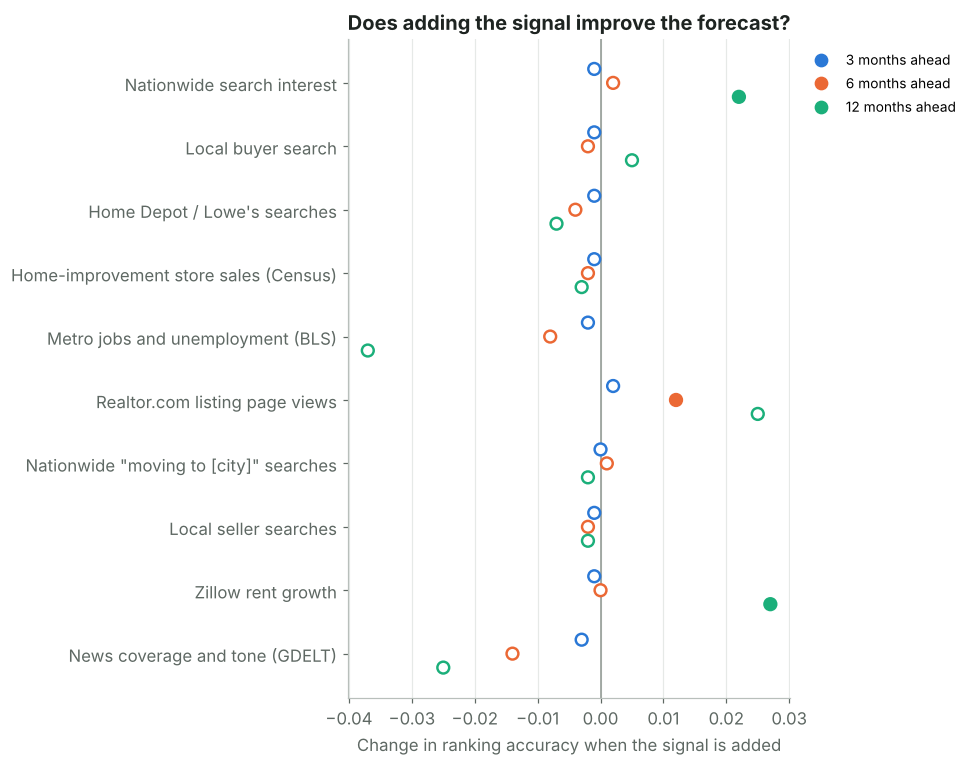

In [7]:
res = pd.read_csv(R + "signal_tests.csv")
HORIZONS, COLS = (3, 6, 12), ["#2a78d6", "#eb6834", "#1baf7a"]
order = list(dict.fromkeys(res["signal"]))[::-1]
fig, ax = plt.subplots(figsize=(9, 0.55 * len(order) + 1.6))
ax.axvline(0, color="#8C958F", lw=1)
for j, h in enumerate(HORIZONS):
    d = res[res["horizon_months"] == h].set_index("signal").reindex(order)
    y = np.arange(len(order)) + (1 - j) * 0.22
    ax.scatter(d["gain"], y, s=60, color=[COLS[j] if hh else "white" for hh in d["helps"].fillna(False)],
               edgecolor=COLS[j], lw=1.6, zorder=3)
ax.set_yticks(np.arange(len(order)), order)
ax.set_xlabel("Change in ranking accuracy when the signal is added")
ax.set_title("Does adding the signal improve the forecast?", loc="left", fontweight="bold", color=INK)
ax.grid(axis="x", color=GRID); ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=COLS[j], mec=COLS[j], ms=8, label=f"{h} months ahead")
                   for j, h in enumerate(HORIZONS)], frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); plt.show()

### 2b. What predicts the next 3 months?
Rank correlation of each part of the score with the next 3 months (0 = no link).

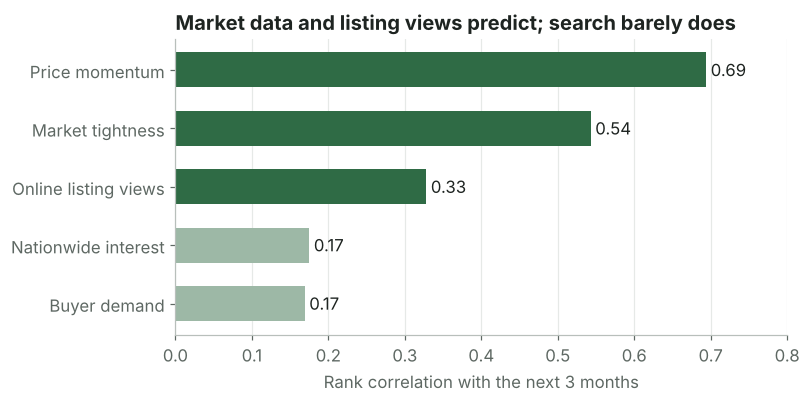

In [8]:
dc = {k: v for k, v in track["driver_rank_corr"].items() if k != "score"}
items = sorted(dc.items(), key=lambda kv: kv[1])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.barh([a for a, _ in items], [b for _, b in items],
               color=[GREEN if b >= 0.3 else "#9DB8A6" for _, b in items], height=0.6)
ax.bar_label(bars, labels=[f"{b:.2f}" for _, b in items], padding=3, color=INK)
ax.axvline(0, color="#8C958F", lw=1); ax.set_xlim(0, 0.8)
ax.set_xlabel("Rank correlation with the next 3 months")
ax.set_title("Market data and listing views predict; search barely does", loc="left", fontweight="bold", color=INK)
ax.grid(axis="x", color=GRID); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

### 2c. How far ahead does search lead prices?
Correlation between a change in search and the price move k months later.

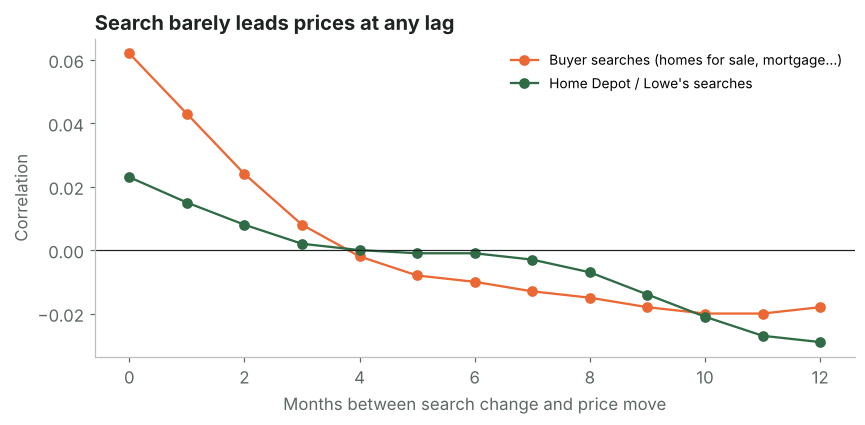

In [9]:
lt = pd.read_csv(R + "lead_time.csv")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lt["months_ahead"], lt["corr_buyer"], "-o", color="#eb6834", label="Buyer searches (homes for sale, mortgage...)")
ax.plot(lt["months_ahead"], lt["corr_homeimp"], "-o", color=GREEN, label="Home Depot / Lowe's searches")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("Months between search change and price move"); ax.set_ylabel("Correlation")
ax.set_title("Search barely leads prices at any lag", loc="left", fontweight="bold", color=INK)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

### 2d. Where search did help: by region
Nationwide \"[city] homes for sale\" searches, 12 months ahead.

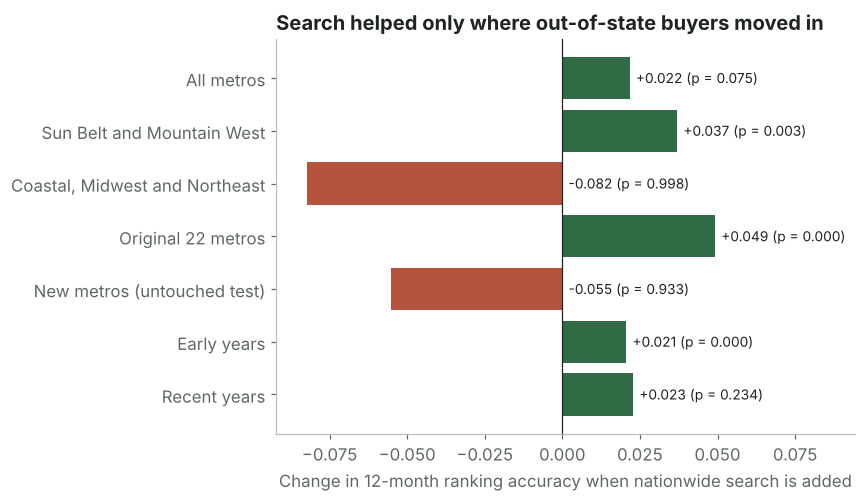

In [10]:
reg = pd.read_csv(R + "search_by_region.csv")
fig, ax = plt.subplots(figsize=(8, 0.5 * len(reg) + 1.2))
ax.barh(reg["check"][::-1], reg["gain"][::-1], color=[GREEN if g > 0 else RED for g in reg["gain"][::-1]])
for y, (g, p) in enumerate(zip(reg["gain"][::-1], reg["p"][::-1])):
    ax.text(max(g, 0) + 0.002, y, f"{g:+.3f} (p = {p:.3f})", va="center", ha="left", fontsize=9, color=INK)
ax.set_xlim(reg["gain"].min() - 0.01, reg["gain"].max() + 0.045)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Change in 12-month ranking accuracy when nationwide search is added")
ax.set_title("Search helped only where out-of-state buyers moved in", loc="left", fontweight="bold", color=INK)
fig.tight_layout(); plt.show()

### 2e. The news test (web content)
Media Cloud news volume and headline tone (VADER plus housing words), added to the score model. Listing views shown for scale.

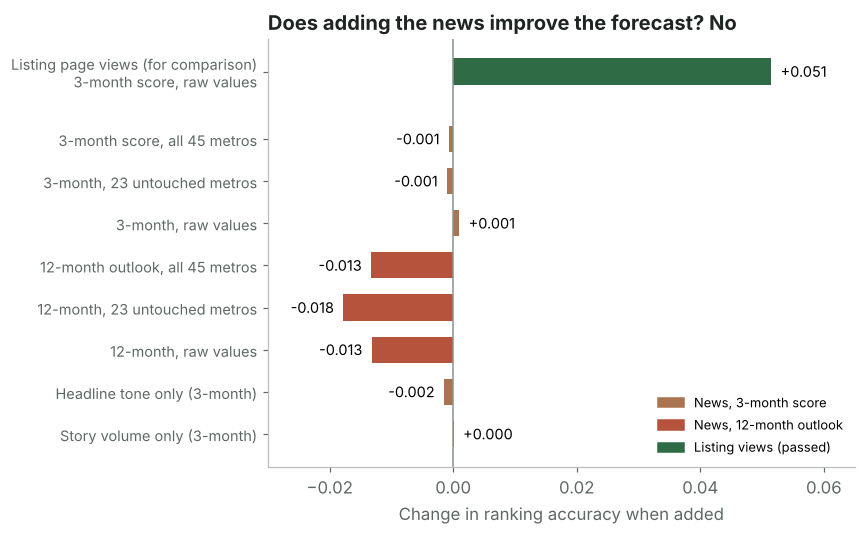

In [11]:
t = pd.read_csv(R + "mediacloud_test.csv")
st = pd.read_csv(R + "stability.csv")
def gain(test, check, version="Main values"):
    return float(t[(t.test == test) & (t.check == check) & (t.version == version)]["gain"].iloc[0])
lv = st[st.finding.str.startswith("Realtor") & (st.check == "All metros") & (st.version == "Raw values")]
rows = [("Listing page views (for comparison)\n3-month score, raw values", float(lv["gain"].iloc[0]), "lv"),
        ("3-month score, all 45 metros", gain("3-month score", "All metros"), "n3"),
        ("3-month, 23 untouched metros", gain("3-month score", "New metros (untouched test)"), "n3"),
        ("3-month, raw values", gain("3-month score", "All metros", "Raw values"), "n3"),
        ("12-month outlook, all 45 metros", gain("12-month outlook", "All metros"), "n12"),
        ("12-month, 23 untouched metros", gain("12-month outlook", "New metros (untouched test)"), "n12"),
        ("12-month, raw values", gain("12-month outlook", "All metros", "Raw values"), "n12"),
        ("Headline tone only (3-month)", gain("3-month score: tone only", "All metros"), "n3"),
        ("Story volume only (3-month)", gain("3-month score: volume only", "All metros"), "n3")]
col = {"lv": GREEN, "n3": "#A9744F", "n12": RED}
fig, ax = plt.subplots(figsize=(8, 5))
ys = [len(rows) - 1 - i + (0.6 if i == 0 else 0) for i in range(len(rows))]
for (lab, g, k), y in zip(rows, ys):
    ax.barh(y, g, height=0.62, color=col[k])
    ax.text(g + (0.0015 if g >= 0 else -0.0015), y, f"{g:+.3f}", va="center", ha="left" if g >= 0 else "right", fontsize=9.5)
ax.set_yticks(ys, [r[0] for r in rows], fontsize=9.5)
ax.axvline(0, color="#8A9490", lw=1); ax.set_xlim(-0.03, 0.065)
ax.set_xlabel("Change in ranking accuracy when added")
ax.set_title("Does adding the news improve the forecast? No", loc="left", fontweight="bold", color=INK)
ax.legend(handles=[Patch(color=col["n3"], label="News, 3-month score"), Patch(color=col["n12"], label="News, 12-month outlook"),
                   Patch(color=col["lv"], label="Listing views (passed)")], loc="lower right", fontsize=8.5, frameon=False)
fig.tight_layout(); plt.show()

### 2f. Headline sentiment example
How VADER plus our housing words scores real headlines (−1 = most negative, +1 = most positive).

In [12]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vaderSentiment"], capture_output=True)
from sentiment import scorers, on_topic
plain, housing = scorers()
heads = pd.read_csv(R + "mediacloud_headlines.csv").dropna(subset=["title"]).drop_duplicates("title")
heads = heads[on_topic(heads)]                      # keep headlines about housing or the city
heads["VADER as is"] = [plain.polarity_scores(h)["compound"] for h in heads["title"]]
heads["VADER + housing words"] = [housing.polarity_scores(h)["compound"] for h in heads["title"]]
changed = heads[(heads["VADER as is"] - heads["VADER + housing words"]).abs() > 0.2]
print(f"{len(heads):,} recent headlines scored; the housing words change the score of {len(changed):,}")
pd.set_option("display.max_colwidth", 90)
changed[["metro", "title", "VADER as is", "VADER + housing words"]].head(10).round(2)

165 recent headlines scored; the housing words change the score of 26


,metro,title,VADER as is,VADER + housing words
11,Austin,Major Texas city leads nation in home price drops as market plunges,0.00,-0.67
15,Baltimore,Early sign of a downturn? San Diego pending home sales plummet as mortgage rates rise,0.00,-0.25
16,Baltimore,Banks seize 42% more homes as Americans fall behind on mortgages — with one state hit ...,0.00,-0.36
20,Birmingham,A tale of two housing markets: Luxury demand surges as affordability squeezes starter-...,-0.13,0.36
24,Boston,"Slow growth, stalling progress: Greater Boston’s housing market gets another bad report",0.38,0.15
32,Buffalo,Home Sales Are Falling Across America. These 10 Cities Are Holding Up Better Than The ...,0.32,0.10
42,Chicago,"Luxury home prices are falling nationwide—except in Florida, where billionaires like J...",0.23,0.00
73,Denver,The hottest new job perk is helping employees buy a house,0.30,0.64
77,Denver,Colorado mountain real estate cools as patience replaces bidding wars,-0.56,0.00
92,Indianapolis,Home prices are dropping the most in these 12 metro areas as inventory piles up,0.00,-0.36


## 3. Model evaluation with logistic regression
Our score model is a ridge regression that predicts *how much* each metro will beat or trail the typical metro. A business often asks a yes/no question instead: **will this metro beat the typical metro over the next 3 months?** Here we evaluate the ridge model as a classifier (yes if its forecast is above 0) and compare it with a logistic regression trained on the same inputs, month by month, using only data available at the time.

In [13]:
from scipy import stats
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from config import ORIGINAL_METROS, HORIZON

panel = pd.read_csv("data/processed/panel.csv", parse_dates=["date"])
fs = pd.read_csv("data/processed/feature_sets.csv", index_col=0)["features"]
cols = fs["A"].split(",") + fs["pageviews"].split(",")          # same inputs as the score
preds = pd.read_csv(R + "predictions.csv", parse_dates=["date"])  # the ridge model's walk-forward forecasts

known = panel.dropna(subset=["target"])
out = []
for m in sorted(preds["date"].unique()):                          # walk forward, one month at a time
    cutoff = pd.Timestamp(m) - pd.DateOffset(months=HORIZON)       # only outcomes known by then
    train = known[known["date"] <= cutoff].dropna(subset=cols)
    test = panel[panel["date"] == m].dropna(subset=cols)
    if len(train) < 200 or train["date"].nunique() < 12 or test.empty:
        continue
    model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
    model.fit(train[cols], (train["target"] > 0).astype(int))
    out.append(pd.DataFrame({"metro": test["metro"].values, "date": m, "Logit": model.predict_proba(test[cols])[:, 1]}))
d = preds.merge(pd.concat(out), on=["metro", "date"]).dropna(subset=["target", "P", "Naive", "Logit"])
d["beat"] = (d["target"] > 0).astype(int)
MODELS = {"Trend continues": ("Naive", 0.0), "Ridge score model (ours)": ("P", 0.0), "Logistic regression": ("Logit", 0.5)}

def nw_pvalue(x, lag):
    # one-sided p-value that the average of x is above 0, Newey-West for overlapping months
    x = np.asarray(x, float); T = len(x); xc = x - x.mean()
    var = xc @ xc / T + 2 * sum((1 - k / (lag + 1)) * (xc[k:] @ xc[:-k]) / T for k in range(1, lag + 1))
    return float(1 - stats.norm.cdf(x.mean() / np.sqrt(var / T)))

def evaluate(g):
    rows, acc_m = [], {}
    for name, (c, cut) in MODELS.items():
        yhat = (g[c] > cut).astype(int)
        acc_m[name] = g.groupby("date").apply(lambda x: accuracy_score(x["beat"], (x[c] > cut).astype(int)))
        rows.append({"model": name, "accuracy": accuracy_score(g["beat"], yhat),
                     "precision": precision_score(g["beat"], yhat), "recall": recall_score(g["beat"], yhat),
                     "AUC": roc_auc_score(g["beat"], g[c]),
                     "ranking accuracy": g.groupby("date").apply(lambda x: spearmanr(x[c], x["target"])[0]).mean(),
                     "top-5 picks that beat avg": g.groupby("date").apply(lambda x: x.nlargest(5, c)["beat"].mean()).mean()})
    t = pd.DataFrame(rows).set_index("model")
    t["p: ridge more accurate"] = [nw_pvalue(acc_m["Ridge score model (ours)"] - acc_m[n], HORIZON)
                                   if not n.startswith("Ridge") else np.nan for n in t.index]
    return t

subsets = {"All 45 metros": d, "23 untouched metros": d[~d["metro"].isin(ORIGINAL_METROS)]}
for name, g in subsets.items():
    print(f"{name}: {len(g):,} metro-months, {g['date'].nunique()} months, {g['beat'].mean():.0%} beat the typical metro")
    display(evaluate(g).round(3))

All 45 metros: 3,314 metro-months, 74 months, 51% beat the typical metro


,accuracy,precision,recall,AUC,ranking accuracy,top-5 picks that beat avg,p: ridge more accurate
model,,,,,,,
Trend continues,0.800,0.804,0.803,0.867,0.727,0.927,0.000
Ridge score model (ours),0.879,0.883,0.879,0.946,0.878,0.995,NaN
Logistic regression,0.867,0.864,0.877,0.938,0.868,0.989,0.003


23 untouched metros: 1,686 metro-months, 74 months, 55% beat the typical metro


,accuracy,precision,recall,AUC,ranking accuracy,top-5 picks that beat avg,p: ridge more accurate
model,,,,,,,
Trend continues,0.767,0.794,0.779,0.842,0.597,0.781,0.000
Ridge score model (ours),0.862,0.873,0.878,0.934,0.793,0.873,NaN
Logistic regression,0.846,0.849,0.875,0.923,0.788,0.859,0.003


### 3a. ROC curves
How well each model separates metros that beat the typical metro from those that don't, at every cut-off (top-left is best).

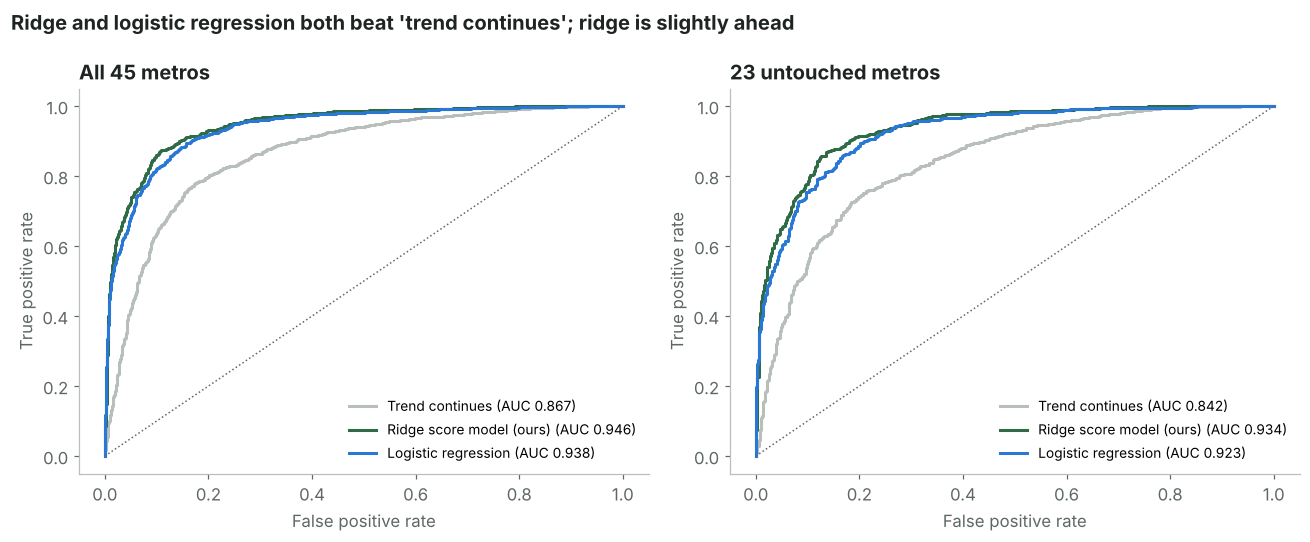

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, g) in zip(axes, subsets.items()):
    for (label, (c, _)), color in zip(MODELS.items(), [GREY, GREEN, BLUE]):
        fpr, tpr, _ = roc_curve(g["beat"], g[c])
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC {roc_auc_score(g['beat'], g[c]):.3f})")
    ax.plot([0, 1], [0, 1], ls=":", color=MUTED, lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(name, loc="left", fontweight="bold", color=INK)
    ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("Ridge and logistic regression both beat 'trend continues'; ridge is slightly ahead",
             x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); plt.show()

### 3b. Confusion matrices (all 45 metros)

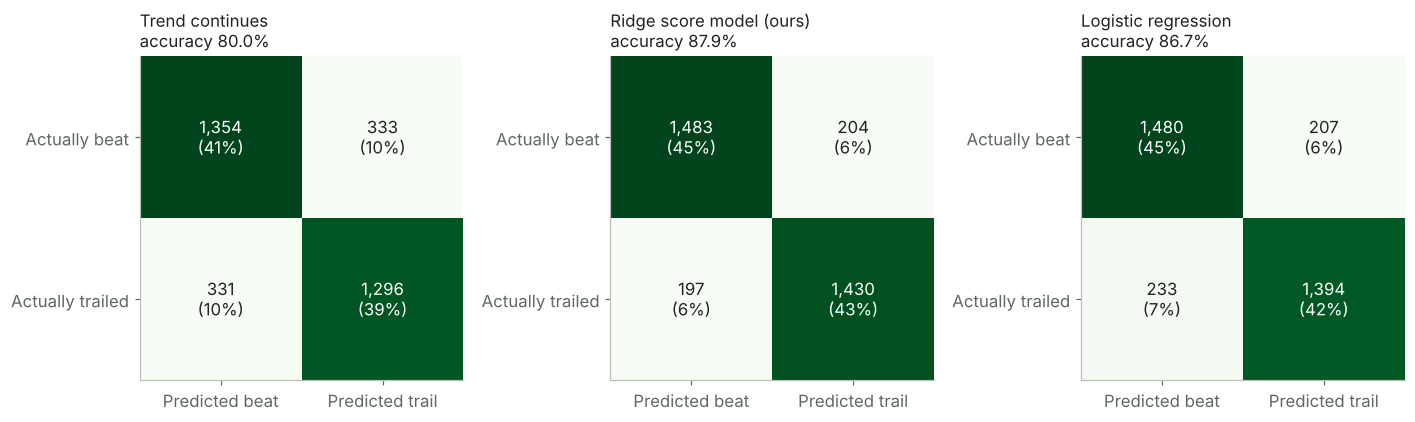

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (label, (c, cut)) in zip(axes, MODELS.items()):
    cm = confusion_matrix(d["beat"], (d[c] > cut).astype(int), labels=[1, 0])
    ax.imshow(cm, cmap="Greens")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.0%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ["Predicted beat", "Predicted trail"]); ax.set_yticks([0, 1], ["Actually beat", "Actually trailed"])
    ax.set_title(f"{label}\naccuracy {accuracy_score(d['beat'], (d[c] > cut).astype(int)):.1%}", loc="left", fontsize=11, color=INK)
fig.tight_layout(); plt.show()

## 4. Dashboard views
The same charts the dashboard shows, from the saved monthly scores.

### 4a. Market map: where each metro has been vs. where it is expected to go

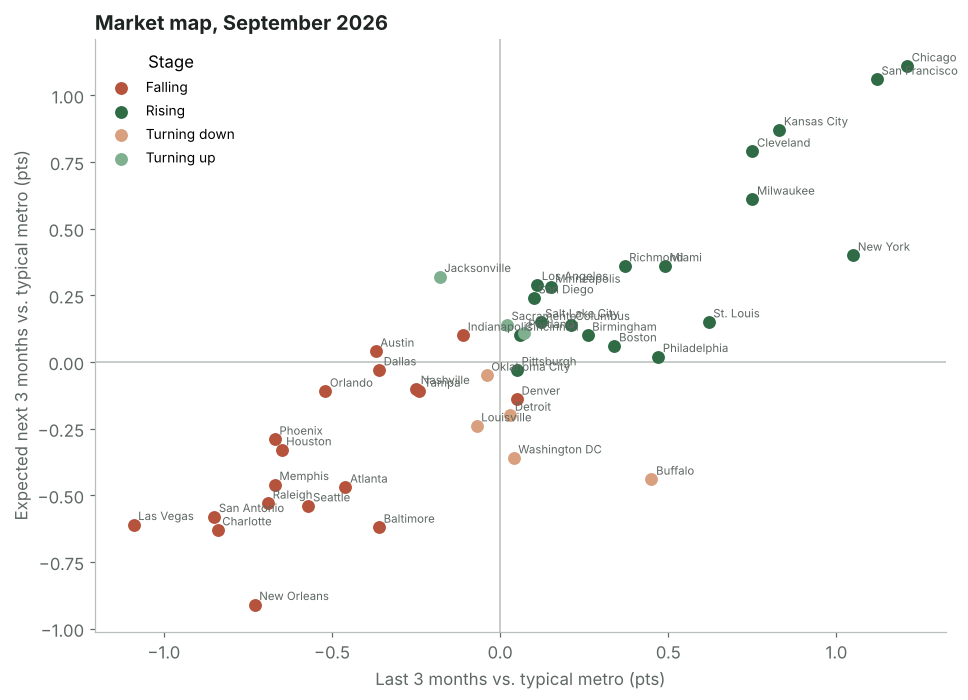

In [16]:
h = pd.read_csv(R + "index_history.csv", parse_dates=["date"])
latest = h[h["date"] == h["date"].max()]
stage_col = {"Rising": GREEN, "Turning up": "#7FB08F", "Turning down": "#D9A07F", "Falling": RED}
fig, ax = plt.subplots(figsize=(9, 6.5))
for s, g in latest.groupby("stage"):
    ax.scatter(g["price_vs_avg"], g["forecast"], s=55, color=stage_col.get(s, GREY), label=s, zorder=3)
for _, r in latest.iterrows():
    ax.annotate(r["metro"], (r["price_vs_avg"], r["forecast"]), fontsize=7.5, color=MUTED, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color=GREY, lw=1); ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel("Last 3 months vs. typical metro (pts)"); ax.set_ylabel("Expected next 3 months vs. typical metro (pts)")
ax.set_title(f"Market map, {latest['date'].max():%B %Y}", loc="left", fontweight="bold", color=INK)
ax.legend(frameon=False, fontsize=9, title="Stage")
fig.tight_layout(); plt.show()

### 4b. One metro's score history
Change `METRO` to any of the 45 metros.

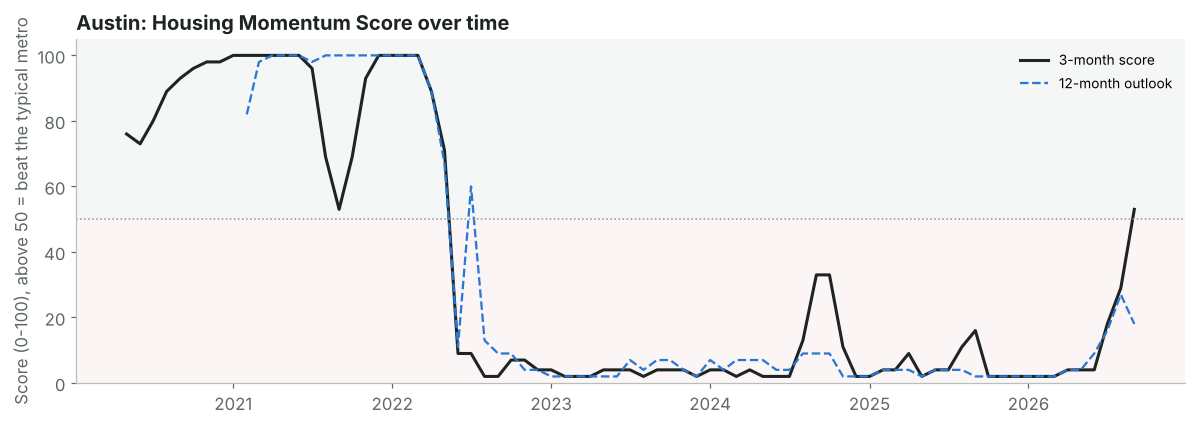

In [17]:
METRO = "Austin"
g = h[h["metro"] == METRO].sort_values("date")
fig, ax = plt.subplots(figsize=(11, 4))
ax.axhspan(50, 105, color=GREEN, alpha=0.05, lw=0); ax.axhspan(0, 50, color=RED, alpha=0.05, lw=0)
ax.plot(g["date"], g["score"], color=INK, lw=2, label="3-month score")
if g["outlook_12m"].notna().any():
    ax.plot(g["date"], g["outlook_12m"], color=BLUE, lw=1.5, ls="--", label="12-month outlook")
ax.axhline(50, color="#8C958F", lw=1, ls=":")
ax.set_ylim(0, 105); ax.set_ylabel("Score (0-100), above 50 = beat the typical metro")
ax.set_title(f"{METRO}: Housing Momentum Score over time", loc="left", fontweight="bold", color=INK)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()